# 03 - Melody -> skyline 
WIP

A melody becomes a **silhouette**: each note is a building whose
x = onset, width = duration, height = pitch. The silhouette's edges drive an off-the-shelf **Stable Diffusion 1.5 + ControlNet (Canny)** to paint a skyline.

Two cases:
1. **Round trip**: the notes we extracted from the Chicago photo in notebook 02 -> silhouette -> generated skyline. Does it look like the original?
2. **Arbitrary melody**: the opening of *Ode to Joy*.

Outputs: `outputs/controlnet/`.

In [1]:
%pip install -q diffusers transformers accelerate opencv-python-headless

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, json
from pathlib import Path
import numpy as np, cv2, torch
import matplotlib.pyplot as plt
from PIL import Image

def setup_env():
    # Colab: Drive folder (SKYLINE_ROOT overrides); local: repo root
    if os.environ.get("SKYLINE_ROOT"):
        return Path(os.environ["SKYLINE_ROOT"])
    try:
        from google.colab import drive, userdata
    except ImportError:
        # kernel cwd varies (notebook dir, repo root, or server root /home/jovyan): search for the project folder
        cwd = Path.cwd()
        for p in (cwd, *cwd.parents, cwd / "work"):
            if (p / "data").is_dir() and (p / "notebooks").is_dir():
                return p
        raise FileNotFoundError(f"Could not find the project root from {cwd}; set SKYLINE_ROOT")
    drive.mount("/content/drive")
    try:
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        pass
    return Path("/content/drive/MyDrive/skyline2music")

ROOT = setup_env()
DATA, OUT = ROOT / "data", ROOT / "outputs"
(OUT / "controlnet").mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(ROOT / "hf_cache"))
device = "cuda" if torch.cuda.is_available() else "cpu"
print("ROOT:", ROOT, "| device:", device)

ROOT: /home/jovyan/work | device: cuda


## Melody -> silhouette
Layers (from the depth-based note layers in notebook 02) are drawn far to near in different grey levels, so overlapping buildings keep visible edges.

cases: ['chicago_roundtrip', 'seattle_roundtrip', 'singapore_roundtrip', 'taipei_roundtrip', 'ode_to_joy']


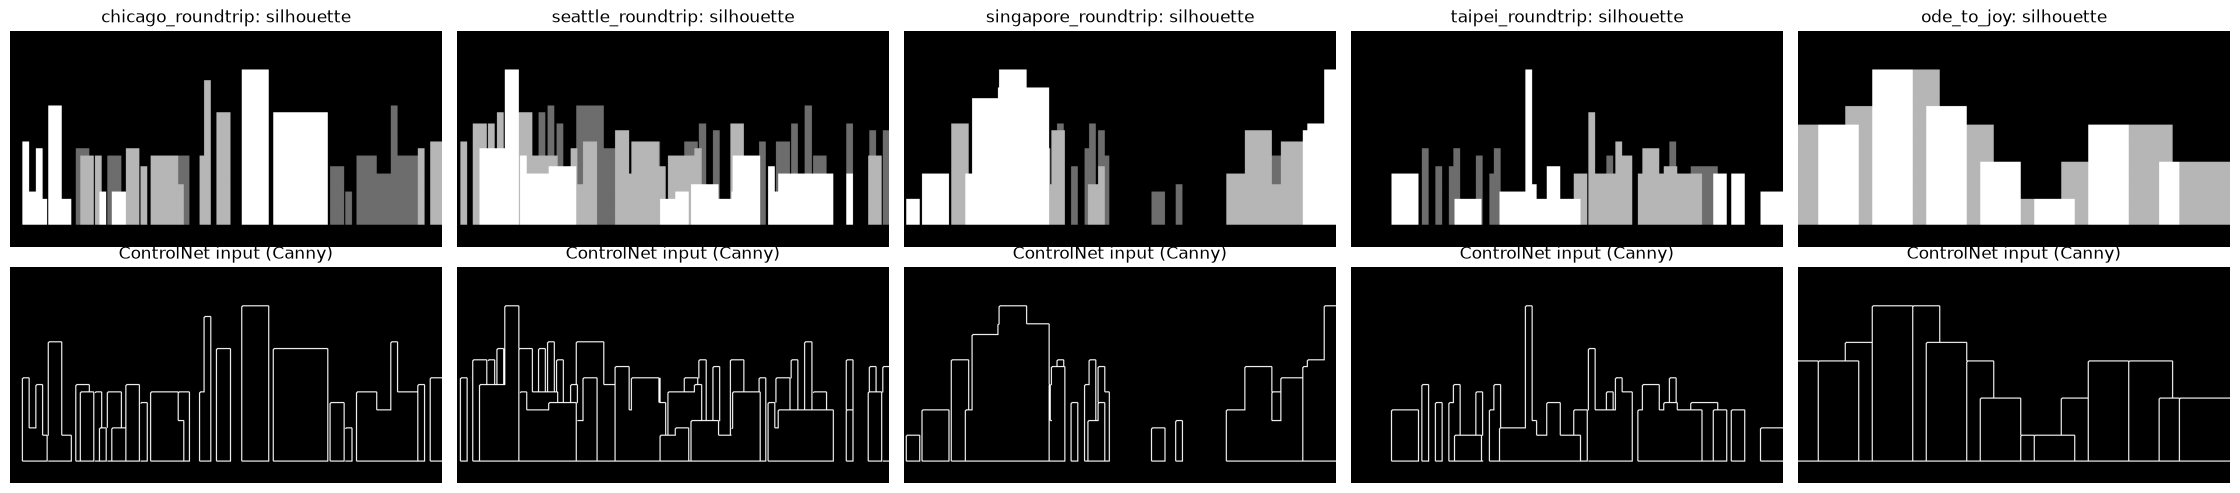

In [3]:
CW, CH = 768, 384            # SD1.5 likes multiples of 8; 2:1 skyline aspect
BASE, MIN_H, MAX_H = 0.90, 0.12, 0.72   # ground line and building height range (fractions of CH)
WIDTH_GAIN = 1.5             # make 1-step buildings visible
GREY = {0: 90, 1: 150, 2: 210}

def silhouette(notes, total_steps, lo, hi):
    img = np.zeros((CH, CW), np.uint8)
    px = CW / total_steps
    for n in sorted(notes, key=lambda n: n["layer"]):
        frac = (n["midi"] - lo) / max(hi - lo, 1)
        h = (MIN_H + (MAX_H - MIN_H) * frac) * CH
        w = max(6, n["dur"] * px * WIDTH_GAIN)
        cx = (n["onset"] + n["dur"] / 2) * px
        x0, x1 = int(max(cx - w / 2, 0)), int(min(cx + w / 2, CW))
        img[int(BASE * CH - h):int(BASE * CH), x0:x1] = GREY[n["layer"]]
    return img

def control_from_silhouette(sil):
    e = cv2.Canny(sil, 20, 60)
    return cv2.dilate(e, np.ones((2, 2), np.uint8))

# one round-trip case per city (notes from notebook 02) + Ode to Joy
cases, refs = {}, {}
for f in sorted((OUT / "music").glob("*_notes.json")):
    city = f.name.replace("_notes.json", "")
    notes = json.load(open(f))["notes"]
    steps = max(n["onset"] + n["dur"] for n in notes)
    key = f"{city}_roundtrip"
    cases[key] = silhouette(notes, steps, min(n["midi"] for n in notes), max(n["midi"] for n in notes))
    refs[key] = next(p for p in DATA.iterdir() if p.stem == city)

# Ode to Joy, opening phrase (midi, steps); quarter = 2 steps; alternate layers so neighbours show an edge
ODE = [(64,2),(64,2),(65,2),(67,2),(67,2),(65,2),(64,2),(62,2),(60,2),(60,2),(62,2),(64,2),(64,3),(62,1),(62,4)]
ode_notes, t = [], 0
for i, (m, du) in enumerate(ODE):
    ode_notes.append(dict(midi=m, onset=t, dur=du, layer=1 + i % 2)); t += du
cases["ode_to_joy"] = silhouette(ode_notes, t, 60, 67)

controls = {k: control_from_silhouette(v) for k, v in cases.items()}
print("cases:", list(cases))

fig, ax = plt.subplots(2, len(cases), figsize=(4.5 * len(cases), 5), squeeze=False)
for c, k in enumerate(cases):
    ax[0, c].imshow(cases[k], cmap="gray"); ax[0, c].set_title(f"{k}: silhouette")
    ax[1, c].imshow(controls[k], cmap="gray"); ax[1, c].set_title("ControlNet input (Canny)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()


## ControlNet generation (SD 1.5 + Canny ControlNet, fp16)

In [4]:
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=torch.float16)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", controlnet=controlnet,
    torch_dtype=torch.float16, safety_checker=None).to(device)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)

PROMPT = ("photo of a city skyline at dusk, tall glass skyscrapers, clear sky, calm water in the foreground, "
          "sharp focus, high quality")
NEG = "lowres, blurry, text, watermark, people, close-up"
SEEDS = [0, 1]

gens = {}
for k, ctrl in controls.items():
    cimg = Image.fromarray(np.stack([ctrl] * 3, -1))
    cimg.save(OUT / "controlnet" / f"{k}_control.png")
    Image.fromarray(cases[k]).save(OUT / "controlnet" / f"{k}_silhouette.png")
    gens[k] = []
    for s in SEEDS:
        g = torch.Generator(device).manual_seed(s)
        im = pipe(PROMPT, image=cimg, negative_prompt=NEG, num_inference_steps=25, guidance_scale=7.5,
                  controlnet_conditioning_scale=1.0, width=CW, height=CH, generator=g).images[0]
        im.save(OUT / "controlnet" / f"{k}_gen_seed{s}.png")
        gens[k].append(im)
print("done; peak VRAM GB:", round(torch.cuda.max_memory_allocated() / 1e9, 1) if device == "cuda" else "n/a")

/opt/conda/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/opt/conda/lib/python3.13/site-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

... (5 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

done; peak VRAM GB: 3.7


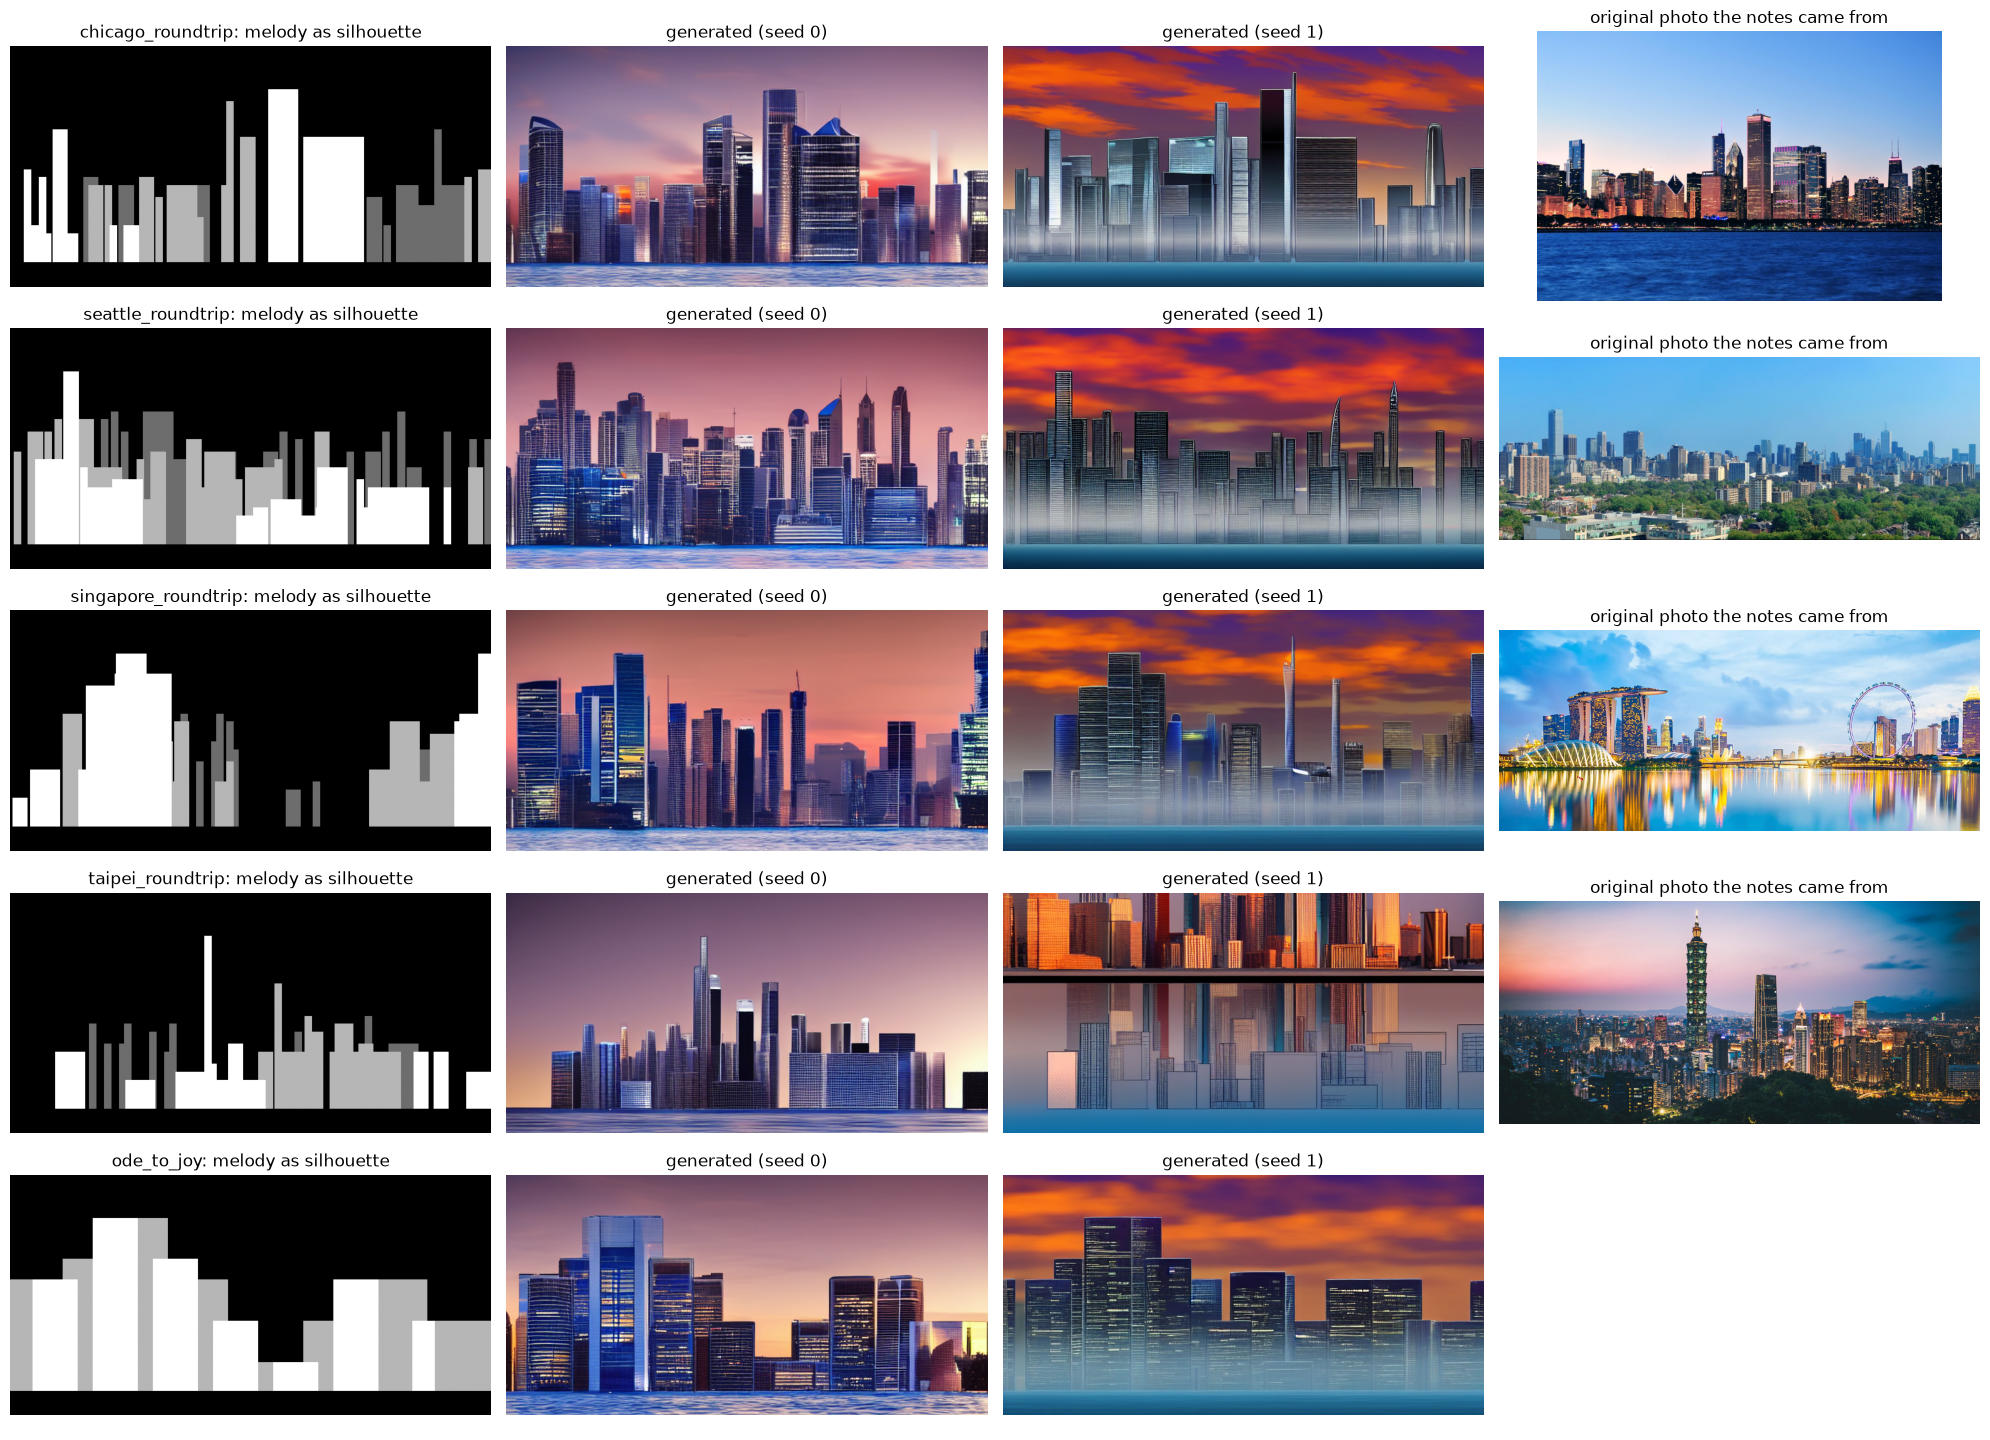

In [5]:
fig, ax = plt.subplots(len(cases), 4, figsize=(20, 2.9 * len(cases)), squeeze=False)
for r, k in enumerate(cases):
    ax[r, 0].imshow(cases[k], cmap="gray"); ax[r, 0].set_title(f"{k}: melody as silhouette")
    ax[r, 1].imshow(gens[k][0]); ax[r, 1].set_title("generated (seed 0)")
    ax[r, 2].imshow(gens[k][1]); ax[r, 2].set_title("generated (seed 1)")
    if k in refs:
        ax[r, 3].imshow(Image.open(refs[k]).convert("RGB")); ax[r, 3].set_title("original photo the notes came from")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
fig.savefig(OUT / "fig_controlnet.png", dpi=120)
plt.show()

## Ground truth vs generated, per city
For each photo: the **original**, the **SAM3 skyline silhouette** taken straight from that photo (the true outline of the buildings we turned into notes),
the **melody silhouette** (what ControlNet actually sees, after the skyline was reduced to one note per building), and the two **generated** skylines.
Comparing columns 2 and 3 shows what the melody encoding throws away; comparing 3 and 4-5 shows how faithfully ControlNet follows the melody.

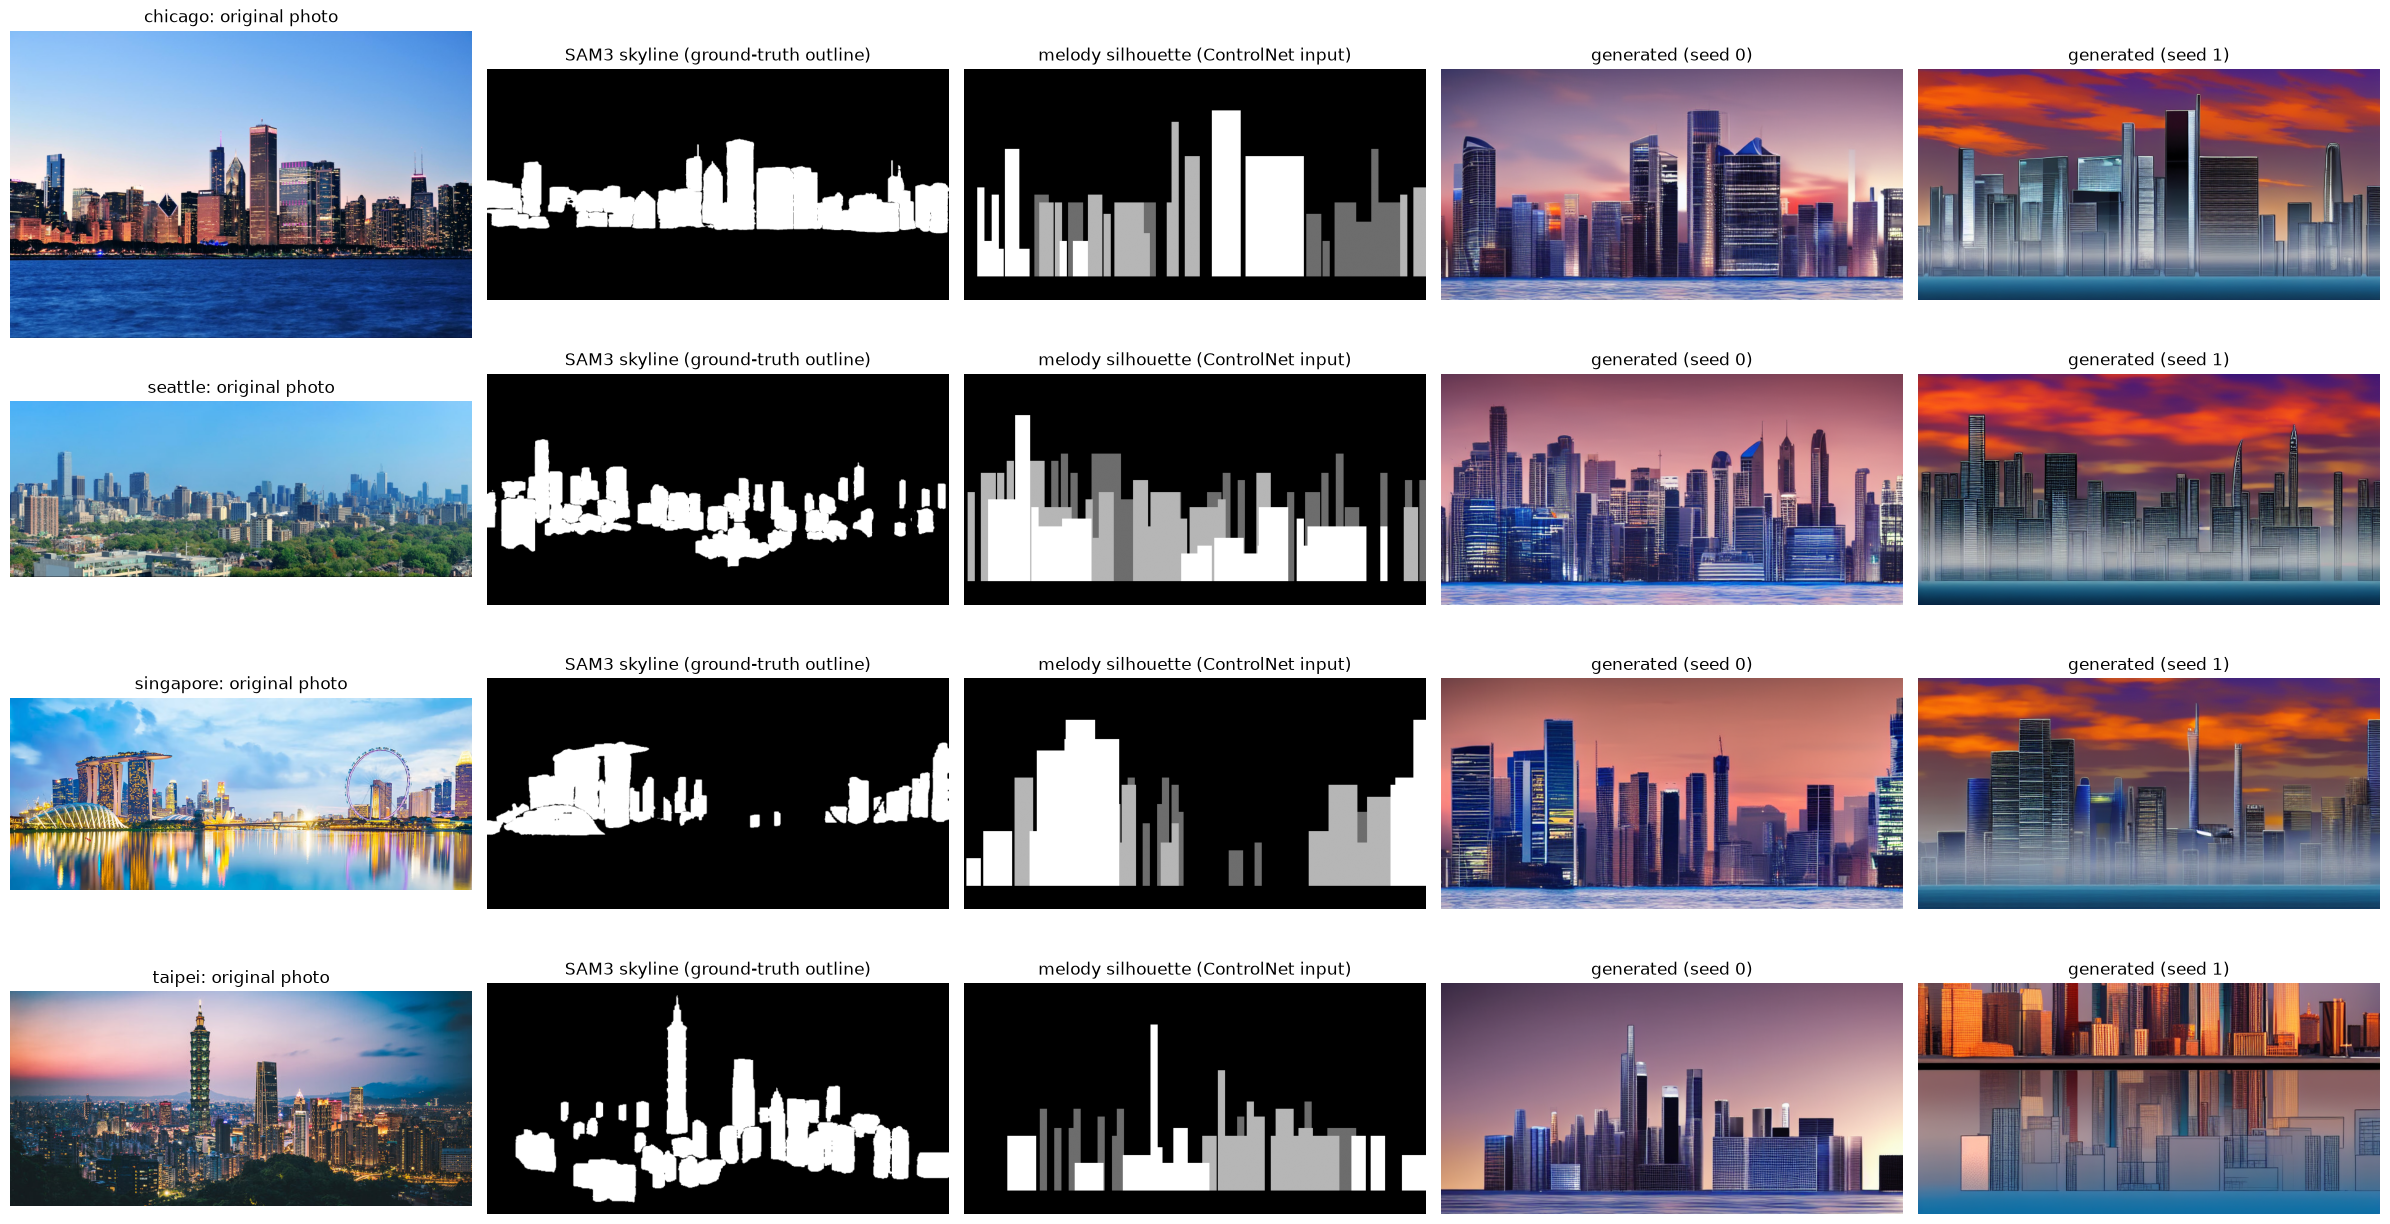

In [6]:
def truth_silhouette(city):
    # union of the building masks that became notes, resized to the same canvas as the melody silhouette
    notes = json.load(open(OUT / "music" / f"{city}_notes.json"))["notes"]
    masks = np.load(OUT / "masks" / f"{city}.npz")["masks"]
    union = np.any([masks[n["mask"]] for n in notes], axis=0).astype(np.uint8) * 255
    return cv2.resize(union, (CW, CH), interpolation=cv2.INTER_AREA)

cities = [k for k in cases if k in refs]
fig, ax = plt.subplots(len(cities), 5, figsize=(24, 3.2 * len(cities)), squeeze=False)
for r, k in enumerate(cities):
    city = k.replace("_roundtrip", "")
    ax[r, 0].imshow(Image.open(refs[k]).convert("RGB")); ax[r, 0].set_title(f"{city}: original photo")
    ax[r, 1].imshow(truth_silhouette(city), cmap="gray"); ax[r, 1].set_title("SAM3 skyline (ground-truth outline)")
    ax[r, 2].imshow(cases[k], cmap="gray"); ax[r, 2].set_title("melody silhouette (ControlNet input)")
    ax[r, 3].imshow(gens[k][0]); ax[r, 3].set_title("generated (seed 0)")
    ax[r, 4].imshow(gens[k][1]); ax[r, 4].set_title("generated (seed 1)")
for a in ax.ravel(): a.axis("off")
plt.tight_layout()
fig.savefig(OUT / "fig_controlnet_vs_truth.png", dpi=110)
plt.show()